# CTD–model comparison in Hvalfjörður (Iceland2)

This notebook compares CTD observations in Hvalfjörður with the 2024 output of the `iceland2_customriver` ROMS-MARBL run on the Iceland2 grid. Observed profiles at stations HV1–HV12 are read from the SEANOE CTD file `ctd_profiles_qc.xlsx` (`seanoe_110439`), and station time series from the HAFRO files `HVIN_1`, `HVNA_1`, `HVNV_1`, `HVSA_1` and `HVSV_1`; model fields are regridded to fixed depth levels with roms-tools. The figures compare salinity, temperature, chlorophyll, oxygen and oxygen saturation as station profiles, along- and across-fjord sections, monthly profiles, depth-bin time series and oxygen Hovmöller diagrams.

## Outline

- **Setup**: imports, file paths and analysis parameters.
- **CTD observations**: read the CTD sheet into an `xarray.Dataset` (station `HV`, depth, time) and compute the mean position of each station.
- **Model temperature and salinity**: regrid `temp` and `salt` from the `output_rst` files, sample the model at the CTD times, compute monthly means and standard deviations, and extract them at the stations.
- **Profiles and sections**: salinity profiles per station and along- and across-fjord salinity sections.
- **Monthly evolution**: monthly temperature and salinity profiles and depth-bin time series.
- **5 m time series**: model temperature and salinity at 5 m compared with the HAFRO station time series.
- **Chlorophyll and oxygen**: model total chlorophyll, oxygen and oxygen saturation compared with observed fluorescence, oxygen and oxygen saturation, including oxygen Hovmöller diagrams at three stations.

CTD observations are filtered to QC flag 2 before they are compared with the model.

## Setup: imports, paths and parameters

Imports (including the local module `roms_regrid.py`) and the main paths and settings used below: the CTD file, the Iceland2 grid, the `iceland2_customriver` output files (`output_his`, `output_rst`, `output_bgc`), the months and observation dates to analyse, the target depth levels, and the temporal thinning factors. The vertical-grid parameters are only needed for a grid made in MATLAB.

In [56]:
# Loading in modules

import subprocess
import os
import pandas as pd
import netCDF4
import numpy as np
import glob
import time
import matplotlib.pyplot as plt
import copy

import xarray as xr
from datetime import datetime, timedelta 
import dask
from scipy.interpolate import griddata
#from ocean_c_lab_tools import *
#from celluloid import Camera 
#import PyCO2SYS as csys
#import seawater as sw
from roms_regrid import *

In [57]:
obs_path='//anvil/projects/x-ees250129/x-uheede/C-Star-in-Hvalfjordur/data/staged/seanoe_hvalfjordur/2026-04-27/seanoe_110439/ctd_profiles_qc/ctd_profiles_qc.xlsx'
model_grid_path="/anvil/scratch/x-uheede/cstar/iceland2_customriver/tasks/segment1/input/input_datasets/Iceland2_NEW_customriver_Iceland2_NEW_256procs_grid.nc"
# Grid parameters, only modify these if grid is made in MATLAB
vert_levels=60
theta_s_model=5
theta_b_model=2
hc_model=300
model_data_path="/anvil/scratch/x-uheede/cstar/iceland2_customriver/gathered_output/output_his.2024??????????.nc"
model_data_path1="/anvil/scratch/x-uheede/cstar/iceland2_customriver/gathered_output/output_rst.2024??????????.nc"
model_data_bgc_path="/anvil/scratch/x-uheede/cstar/iceland2_customriver/gathered_output/output_bgc.2024??????????.nc"

months_analysis=[1,2,3,4,5,6,7,8,9,10,11,12] # enter the months you want to analyze for the model·
# enter the dates you want to analyze for the observations
months_string_begin='01-04-2024'
months_string_end='30-12-2024'
target_depth_levels=[1,2,3,4,5,7,9,10,12,14,15,16,18,20,26,30,36,40,50,80] # Specify depth levels of interest
target_depth_levels_bgc=[1,3,5,8,10,15,20,30]
thinner=24*7 # specify the temporal frequency of data being read (i.e. no need to read in hourly data)
thinner_bgc=7

## CTD observations

The CTD profiles are read from the sheet `CTD_data_Hvalfjordur2024_2025` and reshaped into an `xarray.Dataset` with dimensions `HV` (station), `depth` and `time`. `get_location` returns the time-mean position of stations HV1–HV12, with longitude shifted by +360° to match the model grid.

In [60]:
# define location which calculations the average location of each station
def get_location(obs, hv_values):
    locations = []
    for hv in hv_values:
        lat = obs['lat'].sel(HV=hv).isel(depth=0).mean('time').squeeze().values
        lon = obs['lon'].sel(HV=hv).isel(depth=0).mean('time').squeeze().values + 360
        locations.append([lat, lon])
    return locations

# List of HV values
hv_values = range(1, 13)

# Get the locations
locations = get_location(obs, hv_values)

In [58]:
# Read in observed data
xls = pd.ExcelFile(obs_path)

combo = pd.read_excel(
    xls, 
    'CTD_data_Hvalfjordur2024_2025',
    decimal='.',
    header=25,
    skiprows=[26] 
)

# 1. Create the 'HV' column by removing 'HV' and converting to integer
# We use .str.replace with regex=False for a simple string swap
combo['HV'] = combo['Station_name'].str.replace('HV', '', regex=False).astype(int)

# 2. Create the 'time' column
combo['time'] = pd.to_datetime(combo[['Year_UTC', 'Month_UTC', 'Day_UTC']].rename(
    columns={'Year_UTC': 'year', 'Month_UTC': 'month', 'Day_UTC': 'day'}
))

# 3. Convert to xarray Dataset
obs = xr.Dataset.from_dataframe(combo)

# 4. Reformat using 'HV' as the station index
obs = obs.set_index(index=['HV', 'Depth', 'time'])
obs = obs.drop_duplicates('index')
obs = obs.unstack('index')

# 5. Renaming variables
obs = obs.rename(name_dict={
    'Depth': 'depth',
    'Latitude': 'lat',
    'Longitude': 'lon'
})

## Model temperature and salinity at the CTD stations

The Iceland2 grid is loaded with roms-tools, and `temp` and `salt` from the `output_rst` files are regridded to `target_depth_levels`. The model is sampled at the times nearest to the CTD casts, monthly means and standard deviations are computed for `months_analysis`, and the results are extracted at the 12 station positions (`t_values_combined`, `s_values_combined`).

In [61]:
from roms_tools import Grid, ROMSOutput

In [63]:
grid = Grid.from_file(
    model_grid_path
)

In [64]:
import xarray as xr
import numpy as np

# Load ROMS output using your pattern
roms_output = ROMSOutput(
    grid=grid,
    path=[
        model_data_path1,
    ],
    use_dask=True,
)

ds = roms_output.regrid(var_names=["temp", "salt"],depth_levels=target_depth_levels)
ds = ds.sel(time=~ds.time.to_index().duplicated())
ds_sel = ds.sel(
    time=obs['time'],
    method="nearest"
)

# Extract month for each time entry
months = ds_sel.time.dt.month

# Dimensions we want
month_vals = months_analysis
types = ["mean", "std"]

# Create empty datasets for salt & temp
salt_data = []
temp_data = []

for m in month_vals:
    ds_m = ds_sel.sel(time=months == m)

    # Calculate and append mean & std
    salt_mean = ds_m["salt"].mean("time").load()
    salt_std  = ds_m["salt"].std("time").load()
    temp_mean = ds_m["temp"].mean("time").load()
    temp_std  = ds_m["temp"].std("time").load()

    salt_data.append(xr.concat([salt_mean, salt_std], dim="type"))
    temp_data.append(xr.concat([temp_mean, temp_std], dim="type"))

# Concatenate over month dimension
salt_all = xr.concat(salt_data, dim="month")
temp_all = xr.concat(temp_data, dim="month")

# Assign coordinates
salt_all = salt_all.assign_coords(type=types, month=month_vals)
temp_all = temp_all.assign_coords(type=types, month=month_vals)

# Build final dataset
ds_monthly = xr.Dataset(
    {
        "salt": salt_all,
        "temp": temp_all,
    }
)

print(ds_monthly)



<xarray.Dataset> Size: 3GB
Dimensions:  (lat: 481, lon: 721, depth: 20, type: 2, month: 12)
Coordinates:
  * lat      (lat) float32 2kB 63.0 63.0 63.01 63.01 ... 64.99 64.99 65.0 65.0
  * lon      (lon) float32 3kB 336.0 336.0 336.0 336.0 ... 339.0 339.0 339.0
  * depth    (depth) float32 80B 1.0 2.0 3.0 4.0 5.0 ... 36.0 40.0 50.0 80.0
  * type     (type) <U4 32B 'mean' 'std'
  * month    (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
Data variables:
    salt     (month, type, lat, lon, depth) float64 1GB nan nan nan ... nan nan
    temp     (month, type, lat, lon, depth) float64 1GB nan nan nan ... nan nan


In [66]:
t=ds_monthly['temp']
s=ds_monthly['salt']



In [67]:
# Assuming locations is a list of lat/lon pairs
t_values = []
s_values = []
# Loop over the first 10 locations and store each selection in t_values
for i in range(12):
    lat, lon = locations[i]
    
    # Select the 't' values at the nearest lat/lon
    t_selected = t.sel(lat=lat, method='nearest').sel(lon=lon, method='nearest')
    s_selected = s.sel(lat=lat, method='nearest').sel(lon=lon, method='nearest')
    
    # Store the result in the listx
    t_values.append(t_selected)
    s_values.append(s_selected)

# Combine the selections into an xarray Dataset or DataArray
t_values_combined = xr.concat(t_values, dim='location')
s_values_combined = xr.concat(s_values, dim='location')

# Combine the selections into an xarray Dataset or DataArray
t_values_combined = xr.concat(t_values, dim='location')
s_values_combined = xr.concat(s_values, dim='location')

# Assign a location coordinate for clarity (optional)
t_values_combined = t_values_combined.assign_coords(location=('location', range(1, 13)))
s_values_combined = s_values_combined.assign_coords(location=('location', range(1, 13)))
t_values_combined['depth']=t_values_combined.depth*(-1)
s_values_combined['depth']=s_values_combined.depth*(-1)
# Now you have t_values as an xarray object (Dataset or DataArray)
#print(t_values_combined)


## Salinity profiles and along- and across-fjord sections

Time-mean salinity profiles (± one standard deviation) at each station for model and observations, followed by mean salinity sections along the fjord (stations HV1, 3, 5, 7, 9, 10, 12) and across it (HV6, 7, 8) for observations and model.

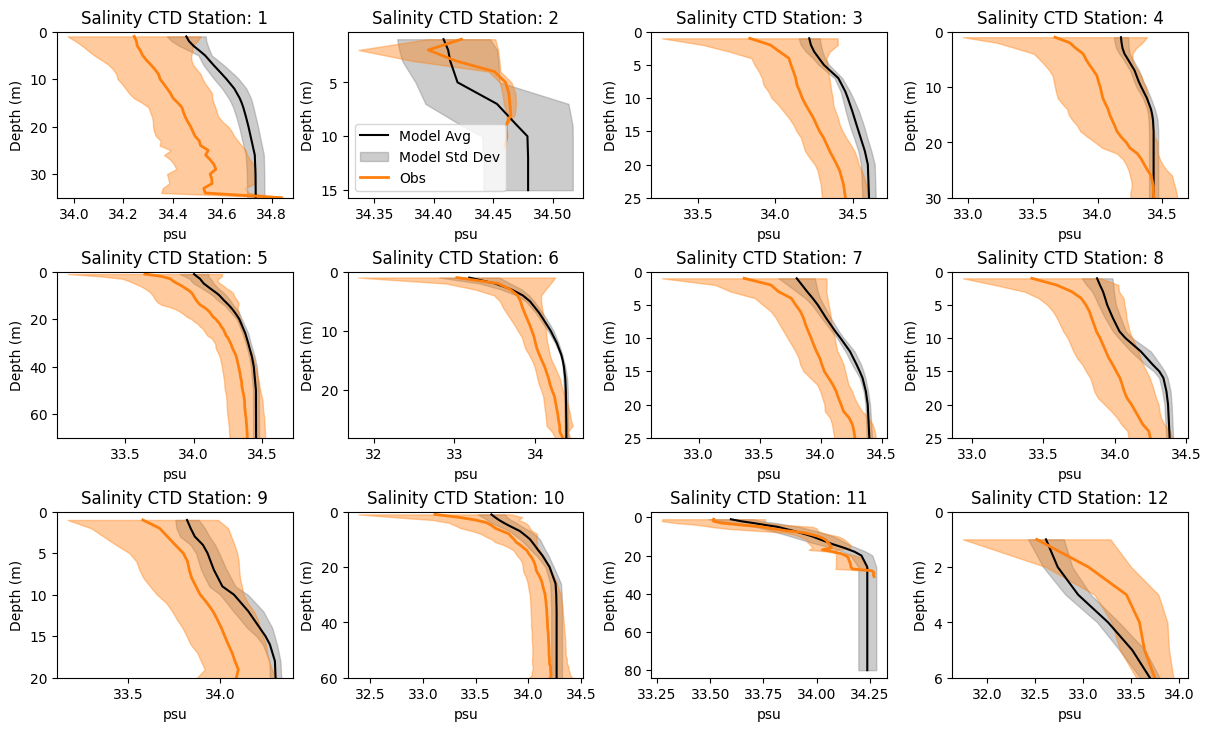

In [68]:
import matplotlib.pyplot as plt

# --- PRE-PROCESSING: Apply QC Flag ---
# Filter salinity to only include values where the flag is 2 (Good Data)
obs_clean = obs.copy()
obs_clean['Salinity_CTD'] = obs_clean['Salinity_CTD'].where(obs_clean['Salinity_CTD_flag'] == 2)

# Set up the subplots
fig, axarr = plt.subplots(nrows=3, ncols=4, figsize=(12, 6*1.2), constrained_layout=True)
ax = axarr.flatten()
palette = plt.get_cmap('tab20')

# Loop through 12 locations
for i in range(12):
    loc = i + 1 

    # --- MODEL DATA ---
    model_mean = s_values_combined.isel(type=0).isel(month=slice(3,9)).mean('month').sel(location=loc)
    model_std = s_values_combined.isel(type=1).isel(month=slice(3,9)).mean('month').sel(location=loc)

    ax[i].plot(model_mean, s_values_combined.depth*(-1), label='Model Avg', color='black')
    ax[i].fill_betweenx(s_values_combined.depth*(-1), model_mean - model_std, model_mean + model_std, 
                         color='grey', alpha=0.4, label='Model Std Dev')

    # --- OBSERVED DATA (Using obs_clean) ---
    # Select the specific station and time range
    obs_loc = obs_clean.sel(HV=loc).sel(time=slice(months_string_begin, months_string_end))
    
    # Calculate Mean and Std Dev
    obs_mean = obs_loc['Salinity_CTD'].mean('time')
    obs_std = obs_loc['Salinity_CTD'].std('time')
    
    # Plot observed average
    ax[i].plot(obs_mean, obs_loc.depth, label='Obs', color=palette(2), linewidth=2)

    # Plot shaded region for observed standard deviation
    ax[i].fill_betweenx(obs_loc.depth, 
                        obs_mean - obs_std, 
                        obs_mean + obs_std, 
                        color=palette(2), alpha=0.4)

    # --- FORMATTING ---
    # Set depth limits for specific subplots
    depth_limits = {0: 35, 2: 25, 3: 30, 4: 70, 5: 28, 6: 25, 7: 25, 8: 20, 9: 60, 11: 6}
    if i in depth_limits:
        ax[i].set_ylim(depth_limits[i], 0) # Note: Inverting via ylim directly
    else:
        ax[i].invert_yaxis()

    ax[i].set_title(f'Salinity CTD Station: {obs_clean.HV.sel(HV=loc).values}')
    ax[i].set_xlabel('psu')
    ax[i].set_ylabel('Depth (m)')

    if i == 1:
        ax[i].legend()

# Display the plot
plt.show()

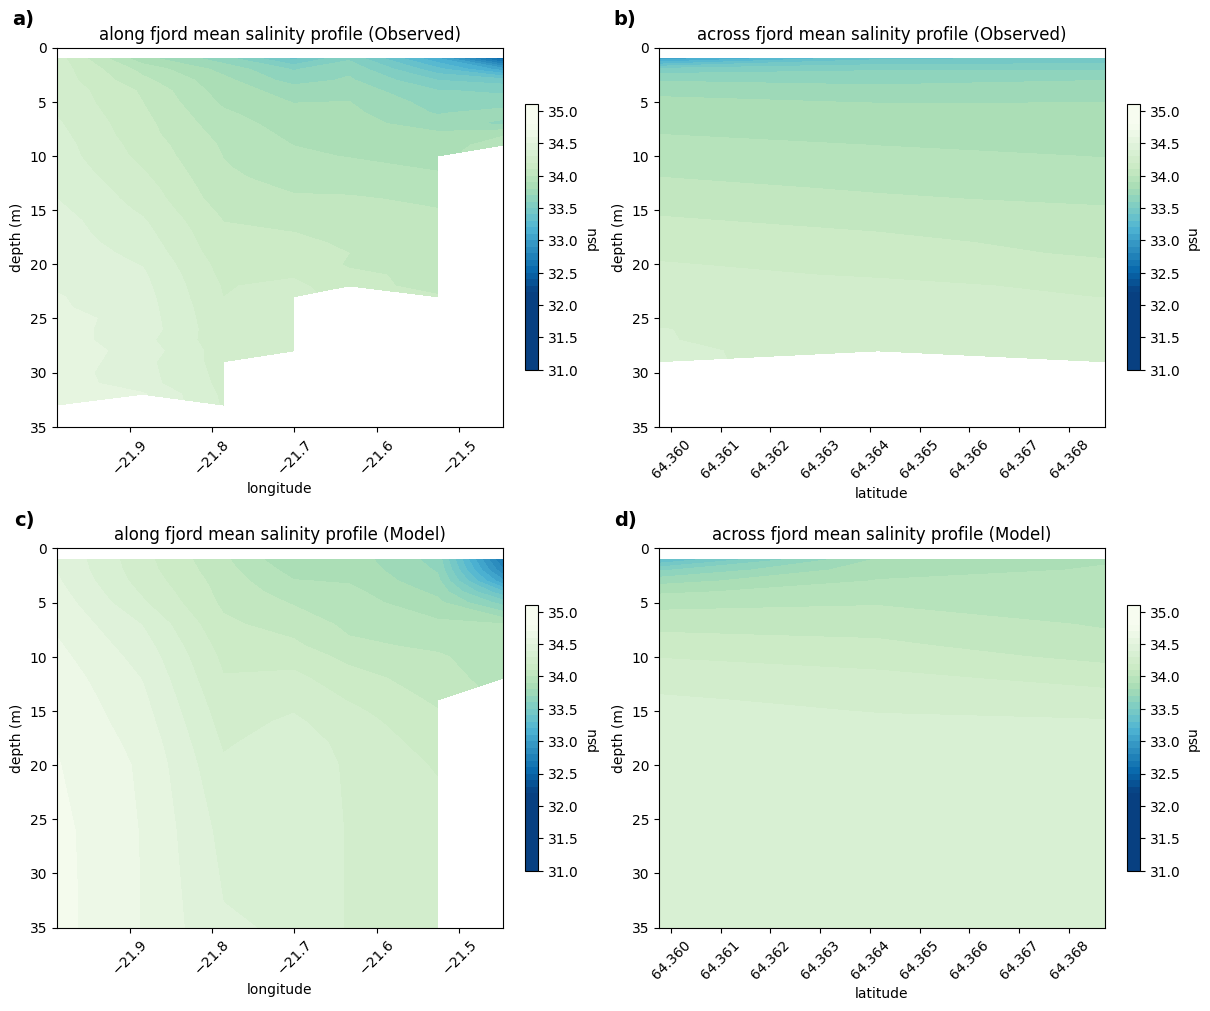

In [69]:
import matplotlib.pyplot as plt
import numpy as np

obs_clean = obs.copy()
obs_clean['Salinity_CTD'] = obs_clean['Salinity_CTD'].where(obs_clean['Salinity_CTD_flag'] == 2)

# --- Setup ---
loc = np.array(locations)
levels_psu = np.arange(31, 35.1, 0.1)

# --- Prepare Data ---
# Observed
data_psu1_obs = obs_clean['Salinity_CTD'].sel(time=slice(months_string_begin, months_string_end)).sel(HV=[1,3,5,7,9,10,12]).mean('time')
data_psu2_obs = obs_clean['Salinity_CTD'].sel(time=slice(months_string_begin, months_string_end)).sel(HV=[6,7,8]).mean('time')

# Model
data_psu1_mod = s_values_combined.isel(type=0).isel(month=slice(3,10)).mean('month').sel(location=[1,3,5,7,9,10,12])
data_psu2_mod = s_values_combined.isel(type=0).isel(month=slice(3,10)).mean('month').sel(location=[6,7,8])

# --- Plotting ---
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(12, 10), constrained_layout=True)
ax = ax.flatten()

# Define plot parameters for iteration to keep code clean
plot_data = [
    (loc[[1-1,3-1,5-1,7-1,9-1,10-1,12-1], 1]-360, data_psu1_obs, 'along fjord mean salinity profile (Observed)', 'longitude'),
    (loc[[6-1,7-1,8-1], 0], data_psu2_obs, 'across fjord mean salinity profile (Observed)', 'latitude'),
    (loc[[1-1,3-1,5-1,7-1,9-1,10-1,12-1], 1]-360, data_psu1_mod, 'along fjord mean salinity profile (Model)', 'longitude'),
    (loc[[6-1,7-1,8-1], 0], data_psu2_mod, 'across fjord mean salinity profile (Model)', 'latitude')
]

labels = ['a)', 'b)', 'c)', 'd)']
cmap='GnBu_r'
for i, (x_coords, data, title, xlabel) in enumerate(plot_data):
    # Handle depth difference between Obs and Model
    depth = data.depth if i < 2 else data.depth * (-1)
    
    # Plot contour
    cf = ax[i].contourf(x_coords, depth, data.transpose(), levels_psu,cmap=cmap, vmin=32.2, vmax= 34.8)
    
    # Formatting
    ax[i].set_title(title)
    ax[i].set_xlabel(xlabel)
    ax[i].set_ylabel('depth (m)')
    ax[i].set_ylim(0, 35)
    ax[i].invert_yaxis()


    # Rotate x-axis labels
    ax[i].tick_params(axis='x', labelrotation=45)   
    # Add Colorbar
    plt.colorbar(cf, ax=ax[i], orientation='vertical', label='psu', shrink=0.7)
    
    # Add Figure Marker (a, b, c, d)
    # transform=ax[i].transAxes uses a 0 to 1 coordinate system for the subplot
    ax[i].text(-0.05, 1.05, labels[i], transform=ax[i].transAxes, 
               fontsize=14, fontweight='bold', va='bottom', ha='right')

plt.show()

## Monthly evolution of temperature and salinity

Monthly mean salinity and temperature profiles for April–November, averaged over stations HV1, HV3–HV10 and HV12, and monthly salinity and temperature averaged over 0–5 m, 10–15 m and 30–40 m for April–December, each for model and observations.

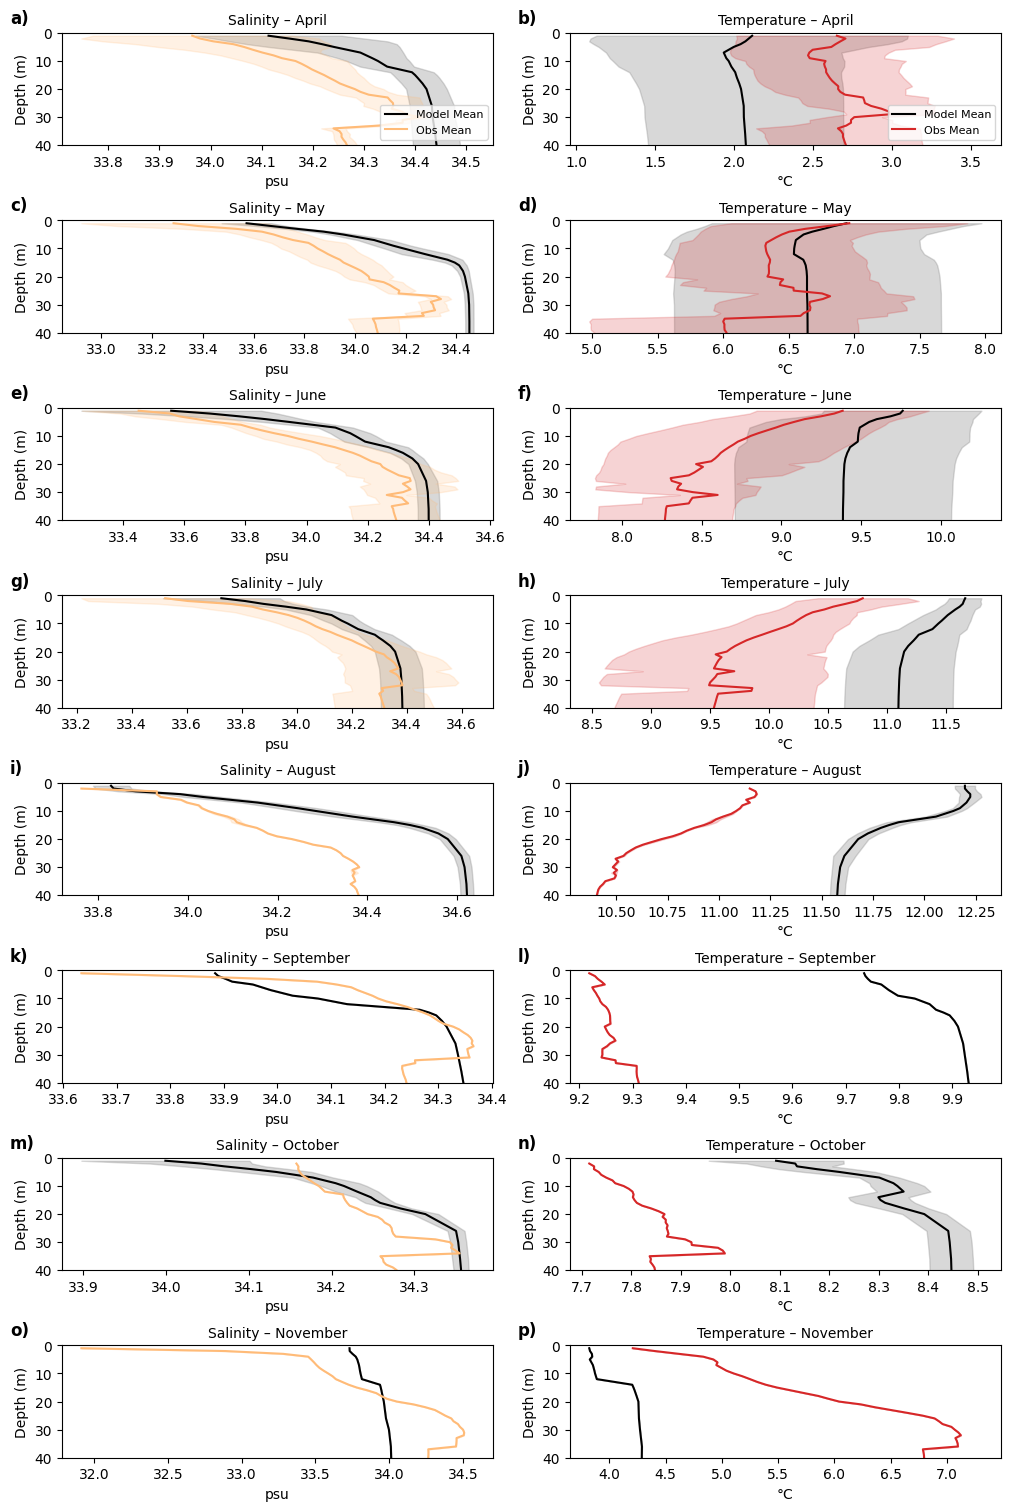

In [70]:
import matplotlib.pyplot as plt
import numpy as np
import string

obs_clean = obs.copy()
obs_clean['Salinity_CTD'] = obs_clean['Salinity_CTD'].where(obs_clean['Salinity_CTD_flag'] == 2)
obs_clean['Temperature_CTD'] = obs_clean['Temperature_CTD'].where(obs_clean['TEMP_flag'] == 2)

# --- CONFIG ---
month_names = ["April", "May", "June", "July", "August","September","October","November"]
n_months = 8
palette = plt.get_cmap("tab20")
locations_idx = [1, 3, 4, 5, 6, 7, 8, 9, 10, 12]

# --- PREPARE DATA ---
# Model (Salinity & Temperature)
mod_s_mean = s_values_combined.isel(type=0).isel(month=slice(3,11)).sel(location=locations_idx).mean(dim="location")
mod_s_std  = s_values_combined.isel(type=1).isel(month=slice(3,11)).sel(location=locations_idx).mean(dim="location")

mod_t_mean = t_values_combined.isel(type=0).isel(month=slice(3,11)).sel(location=locations_idx).mean(dim="location")
mod_t_std  = t_values_combined.isel(type=1).isel(month=slice(3,11)).sel(location=locations_idx).mean(dim="location")

# Observations Lists
obs_s_mean_list, obs_s_std_list = [], []
obs_t_mean_list, obs_t_std_list = [], []

for m in range(n_months):
    month_str = f"2024-{m+3:02d}"
    # Use generic slice to capture the whole month
    obs_sel = obs_clean.sel(time=slice(f'2024-{m+4:02d}-01', f'2024-{m+4:02d}-30'))
    
    # Salinity Processing
    s_mean = obs_sel['Salinity_CTD'].mean(dim="time").sel(HV=locations_idx).mean(dim="HV")
    s_std  = obs_sel['Salinity_CTD'].std(dim="time").sel(HV=locations_idx).mean(dim="HV")
    obs_s_mean_list.append(s_mean)
    obs_s_std_list.append(s_std)
    
    # Temperature Processing
    t_mean = obs_sel["Temperature_CTD"].mean(dim="time").sel(HV=locations_idx).mean(dim="HV")
    t_std  = obs_sel["Temperature_CTD"].std(dim="time").sel(HV=locations_idx).mean(dim="HV")
    obs_t_mean_list.append(t_mean)
    obs_t_std_list.append(t_std)

# --- SET UP FIGURE (5 rows x 2 columns) ---
fig, axes = plt.subplots(nrows=8, ncols=2, figsize=(10, 15), constrained_layout=True)

alphabet = list(string.ascii_lowercase)

for m in range(n_months):
    for col in range(2):
        ax = axes[m, col]
        idx = m * 2 + col  # For a), b), c)... indexing
        
        if col == 0: # SALINITY COLUMN
            mod_m, mod_s = mod_s_mean.isel(month=m), mod_s_std.isel(month=m)
            obs_m, obs_s = obs_s_mean_list[m], obs_s_std_list[m]
            units, title_var = "psu", "Salinity"
            color_obs = palette(3) # Blue-ish
        else: # TEMPERATURE COLUMN
            mod_m, mod_s = mod_t_mean.isel(month=m), mod_t_std.isel(month=m)
            obs_m, obs_s = obs_t_mean_list[m], obs_t_std_list[m]
            units, title_var = "°C", "Temperature"
            color_obs = palette(6) # Red-ish

        # Plot Model
        ax.plot(mod_m, s_values_combined.depth*(-1), color='black', label="Model Mean", lw=1.5)
        ax.fill_betweenx(s_values_combined.depth*(-1), mod_m - mod_s, mod_m + mod_s, color="grey", alpha=0.3)

        # Plot Observations
        ax.plot(obs_m, obs.depth, color=color_obs, label="Obs Mean", lw=1.5)
        ax.fill_betweenx(obs.depth, obs_m - obs_s, obs_m + obs_s, color=color_obs, alpha=0.2)

        # Formatting
        ax.set_title(f"{title_var} – {month_names[m]}", fontsize=10)
        ax.set_xlabel(units)
        ax.set_ylabel("Depth (m)")
        ax.set_ylim(0, 40)
        ax.invert_yaxis()
        
        # Add Figure Marker (a, b, c...)
        ax.text(-0.12, 1.05, f"{alphabet[idx]})", transform=ax.transAxes, 
                fontsize=12, fontweight='bold', va='bottom')

        # Legend only on the first row
        if m == 0:
            ax.legend(fontsize=8, loc='lower right')

plt.show()

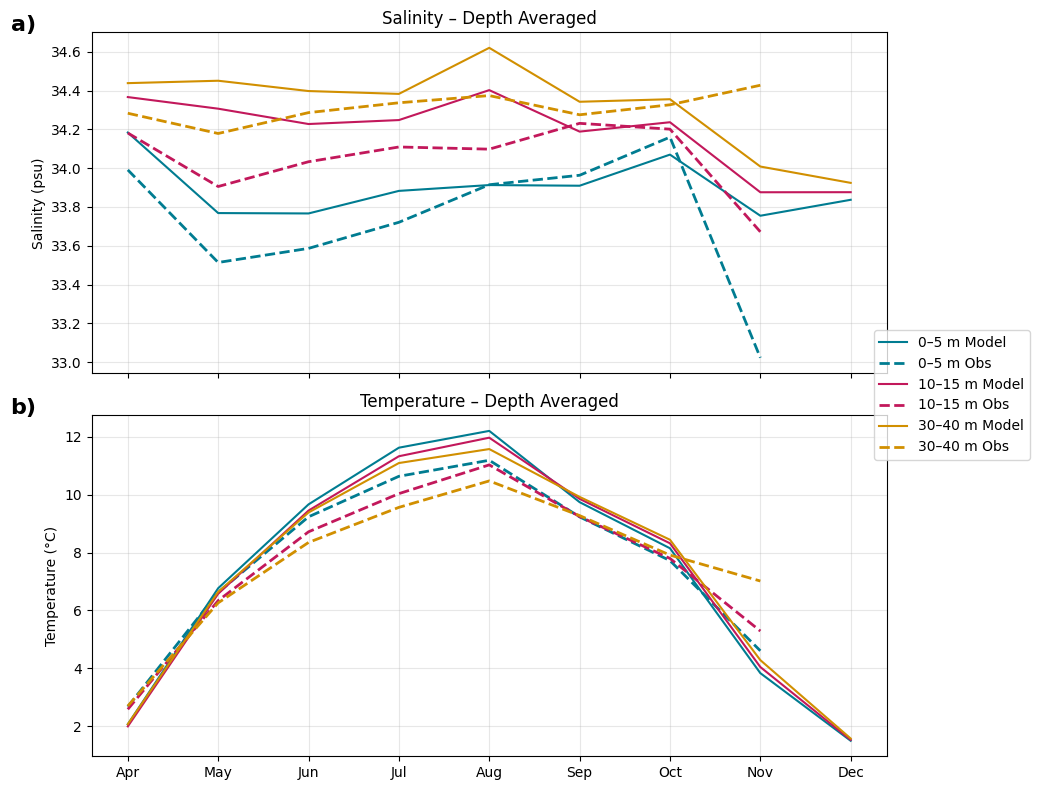

In [71]:
# Depth bins
depth_bins = {
    "0–5 m": (0, 5),
    "10–15 m": (10, 15),
    "30–40 m": (30, 40)
}

locations_idx = [1, 3, 4, 5, 6, 7, 8, 9, 10, 12]

# Select model mean (type=0) and desired months
mod_s = s_values_combined.isel(type=0).isel(month=slice(3,12)).sel(location=locations_idx).mean("location")
mod_t = t_values_combined.isel(type=0).isel(month=slice(3,12)).sel(location=locations_idx).mean("location")


months = np.arange(mod_s.month.size)

model_sal = {}
model_temp = {}

for label, (zmin, zmax) in depth_bins.items():
    model_sal[label] = mod_s.sel(depth=slice(zmin*(-1), zmax*(-1))).mean("depth")
    model_temp[label] = mod_t.sel(depth=slice(zmin*(-1), zmax*(-1))).mean("depth")


obs_sal = {}
obs_temp = {}

for label, (zmin, zmax) in depth_bins.items():
    sal_list = []
    temp_list = []

    for m in range(9):
        obs_sel = obs.sel(
            time=slice(f'2024-{m+4:02d}-01', f'2024-{m+4:02d}-30')
        ).sel(HV=locations_idx)

        sal_mean = (
            obs_sel["Salinity_CTD"].where(obs_sel['Salinity_CTD_flag'] == 2)
            .sel(depth=slice(zmin, zmax))
            .mean(("depth","time","HV"))
        )

        temp_mean = (
            obs_sel["Temperature_CTD"].where(obs_sel['TEMP_flag'] == 2)
            .sel(depth=slice(zmin, zmax))
            .mean(("depth","time","HV"))
        )

        sal_list.append(sal_mean)
        temp_list.append(temp_mean)

    obs_sal[label] = np.array(sal_list)
    obs_temp[label] = np.array(temp_list)

import matplotlib.pyplot as plt
import numpy as np

# Color map for depth bins
colors = {
    "0–5 m": "#007C91",   # deep teal
    "10–15 m": "#C2185B", # strong magenta
    "30–40 m": "#D18F00"  # warm golden
}

fig, axes = plt.subplots(2, 1, figsize=(9,8), sharex=True)

# =====================
# SALINITY
# =====================
ax = axes[0]

for label in depth_bins.keys():

    color = colors[label]

    # --- Model ---
    model_vals = np.array(model_sal[label])
    valid_model = ~np.isnan(model_vals)

    ax.plot(months[valid_model],
            model_vals[valid_model],
            color=color,
            linestyle="-",
            label=f"{label} Model")

    # --- Observations ---
    obs_vals = np.array(obs_sal[label])
    valid_obs = ~np.isnan(obs_vals)

    ax.plot(months[valid_obs],
            obs_vals[valid_obs],
            color=color,
            linestyle="--",
            linewidth=2,
            label=f"{label} Obs")

ax.set_ylabel("Salinity (psu)")
ax.set_title("Salinity – Depth Averaged")
ax.grid(alpha=0.3)
ax.text(-0.07, 1.05, 'a)', transform=ax.transAxes, fontsize=16, fontweight='bold', va='top', ha='right')

# =====================
# TEMPERATURE
# =====================
ax = axes[1]

for label in depth_bins.keys():

    color = colors[label]

    # --- Model ---
    model_vals = np.array(model_temp[label])
    valid_model = ~np.isnan(model_vals)

    ax.plot(months[valid_model],
            model_vals[valid_model],
            color=color,
            linestyle="-",
            label=f"{label} Model")

    # --- Observations ---
    obs_vals = np.array(obs_temp[label])
    valid_obs = ~np.isnan(obs_vals)

    ax.plot(months[valid_obs],
            obs_vals[valid_obs],
            color=color,
            linestyle="--",
            linewidth=2,
            label=f"{label} Obs")

ax.set_ylabel("Temperature (°C)")
ax.set_title("Temperature – Depth Averaged")
ax.grid(alpha=0.3)

# Add Subplot Label a)


# Add Subplot Label b)
axes[1].text(-0.07, 1.05, 'b)', transform=ax.transAxes, fontsize=16, fontweight='bold', va='top', ha='right')

# =====================
# Shared X-axis
# =====================
axes[1].set_xticks(months)
axes[1].set_xticklabels(["Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])

# =====================
# Single Combined Legend
# =====================
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center right",bbox_to_anchor=(1.15, 0.5))

plt.tight_layout()
plt.show()



## 5 m time series: model vs HAFRO station data

Model temperature and salinity are regridded at 5 m, thinned to every 24th output time and extracted at the CTD station positions. They are compared with the HAFRO station time series `HVIN_1`, `HVNA_1`, `HVNV_1`, `HVSA_1` and `HVSV_1` (`*_TS.nc`), both as an average over stations and for model station 1 against `HVSV_1`.

In [72]:
import xarray as xr
import numpy as np

# Load ROMS output using your pattern
roms_output = ROMSOutput(
    grid=grid,
    path=[
        model_data_path1,
    ],
    use_dask=True,
)

ds = roms_output.regrid(var_names=["temp", "salt"],depth_levels=[5])


In [73]:
t=ds['temp'].thin({'time': 24}).load()
s=ds['salt'].thin({'time': 24}).load()

In [74]:
# Define file paths and station names
stations = ["HVIN_1", "HVNA_1", "HVNV_1", "HVSA_1", "HVSV_1"]
file_paths = {name: f"/global/cfs/cdirs/m4632/uheede/Hafro_obsdata/{name}new.nc" for name in stations}
# Define file paths and station names
stations = ["HVIN_1", "HVNA_1", "HVNV_1", "HVSA_1", "HVSV_1"]
file_paths = {name: f"/home/x-uheede/R/HAFRO/{name}_TS.nc" for name in stations}

# Dictionary to store datasets
datasets = {}

for name, path in file_paths.items():
    ds = xr.open_dataset(path)
    
    # Store dataset with adjusted longitude
    datasets[name] = ds.assign_coords(lon=ds['lon'].load() + 360)

subtract = 739674 - 9189  # Computed constant
reference_date = pd.to_datetime("2000-01-01")  # Reference date

# Apply transformation to all datasets
for name, ds in datasets.items():
    datetime_series = reference_date + pd.to_timedelta((ds['time'].values - subtract), unit='D')
    datasets[name] = ds.assign_coords(time_dim=datetime_series)  # Update the time coordinate

ds_list = []

for name, ds in datasets.items():
    # Add station as a new dimension
    ds_expanded = ds.expand_dims(station=[name])
    ds_list.append(ds_expanded)
    
combined = xr.concat(ds_list, dim="station")
mean_ts = combined.mean(dim="station", skipna=True)

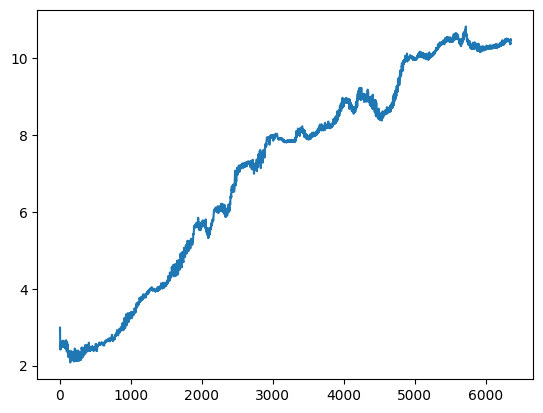

In [75]:
plt.plot(mean_ts['temperature'])

In [76]:
# Assuming locations is a list of lat/lon pairs
t_values = []
s_values = []
# Loop over the first 10 locations and store each selection in t_values
for i in range(12):
    lat, lon = locations[i]
    
    # Select the 't' values at the nearest lat/lon
    t_selected = t.sel(lat=lat, method='nearest').sel(lon=lon, method='nearest')
    s_selected = s.sel(lat=lat, method='nearest').sel(lon=lon, method='nearest')
    
    # Store the result in the listx
    t_values.append(t_selected)
    s_values.append(s_selected)

# Combine the selections into an xarray Dataset or DataArray
t_values_combined = xr.concat(t_values, dim='location')
s_values_combined = xr.concat(s_values, dim='location')

# Assign a location coordinate for clarity (optional)
t_values_combined = t_values_combined.assign_coords(location=('location', range(1, 13)))
s_values_combined = s_values_combined.assign_coords(location=('location', range(1, 13)))
#t_values_combined['depth']=t_values_combined.depth*(-1)
#s_values_combined['depth']=s_values_combined.depth*(-1)
# Now you have t_values as an xarray object (Dataset or DataArray)
#print(t_values_combined)


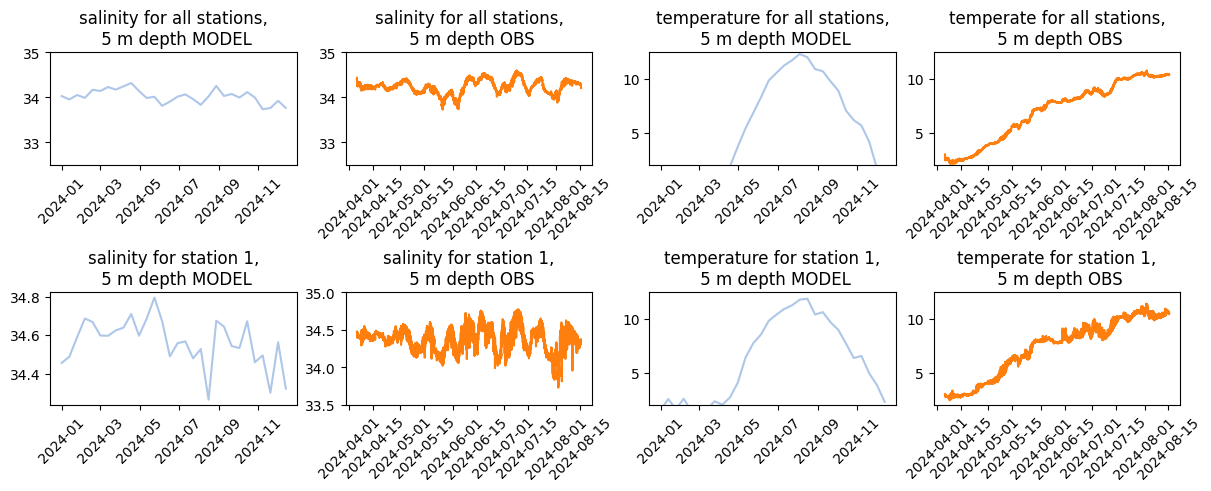

In [77]:
import matplotlib.pyplot as plt

# Set up the subplots
fig, axarr = plt.subplots(nrows=2, ncols=4, figsize=(12, 4*1.2), constrained_layout=True)
ax = axarr.flatten()  # Flatten to make indexing easier
palette = plt.get_cmap('tab20')

# Plot observed salinity for May 2024
ax[1].plot(mean_ts['salinity'].time_dim.sel(time_dim=slice('04-01-2024', '09-01-2024')),
           mean_ts['salinity'].sel(time_dim=slice('04-01-2024', '09-01-2024')),
           label='May', color=palette(2))
ax[1].set_ylim(32.5,35)

ax[0].plot(s_values_combined.time, s_values_combined.sel(location=[1,3,4,5,6,7,8,9,10,12]).mean('location'),
           label='May', color=palette(1))
ax[0].set_ylim(32.5,35)

ax[3].set_ylim(2,12.5)

# Plot observed salinity for May 2024
ax[3].plot(mean_ts['temperature'].time_dim.sel(time_dim=slice('04-01-2024', '09-01-2024')),
           mean_ts['temperature'].sel(time_dim=slice('04-01-2024', '09-01-2024')),
           label='May', color=palette(2))
ax[3].set_ylim(2,12.5)

ax[2].plot(s_values_combined.time, t_values_combined.sel(location=[1,3,4,5,6,7,8,9,10,12]).mean('location'),
           label='May', color=palette(1))
ax[2].set_ylim(2,12.5)
ax[5].plot(datasets['HVSV_1'].time_dim.sel(time_dim=slice('04-01-2024', '09-01-2024')),
           datasets['HVSV_1']['salinity'].sel(time_dim=slice('04-01-2024', '09-01-2024')),
           label='May', color=palette(2))
ax[5].set_ylim(33.5,35)

ax[4].plot(s_values_combined.time, s_values_combined.sel(location=[1]).mean('location'),
           label='May', color=palette(1))
ax[5].set_ylim(33.5,35)

# Plot observed salinity for May 2024
ax[7].plot(datasets['HVSV_1'].time_dim.sel(time_dim=slice('04-01-2024', '09-01-2024')),
           datasets['HVSV_1']['temperature'].sel(time_dim=slice('04-01-2024', '09-01-2024')),
           label='May', color=palette(2))
ax[7].set_ylim(2,12.5)
ax[6].plot(s_values_combined.time, t_values_combined.sel(location=[1]).mean('location'),
           label='May', color=palette(1))
ax[6].set_ylim(2,12.5)
# Rotate x-axis labels for all subplots
for a in ax:
    a.tick_params(axis='x', rotation=45)  # Adjust rotation angle as needed
    
    
ax[0].set_title('salinity for all stations,\n 5 m depth MODEL')
ax[1].set_title('salinity for all stations,\n 5 m depth OBS')
ax[2].set_title('temperature for all stations,\n 5 m depth MODEL')
ax[3].set_title('temperate for all stations,\n 5 m depth OBS')
ax[4].set_title('salinity for station 1,\n 5 m depth MODEL')
ax[5].set_title('salinity for station 1,\n 5 m depth OBS')
ax[6].set_title('temperature for station 1,\n 5 m depth MODEL')
ax[7].set_title('temperate for station 1,\n 5 m depth OBS')
plt.show()



## Chlorophyll and oxygen

Model `spChl`, `diatChl` and `O2` from the `output_bgc` files and `temp` from the `output_rst` files are regridded to `target_depth_levels_bgc` and thinned in time. Total chlorophyll (`spChl` + `diatChl`), oxygen and temperature are extracted at the station positions, then averaged over stations and over 0–5 m, 5–15 m and 15–30 m. Oxygen saturation is computed with `gsw.O2sol_SP_pt` from model temperature and a fixed salinity of 34.

In [78]:
roms_output_bgc = ROMSOutput(
    grid=grid,
    path=[
        model_data_bgc_path,
    ],
    use_dask=True,
)

roms_output_temp = ROMSOutput(
    grid=grid,
    path=[
        model_data_path1,
    ],
    use_dask=True,
)


In [79]:
var_names=["spChl","diatChl",'O2']

In [80]:
bgc = roms_output_bgc.regrid(depth_levels=target_depth_levels_bgc,var_names=var_names)
temp= roms_output_temp.regrid(depth_levels=target_depth_levels_bgc,var_names=["temp"])
temp = temp.sel(time=bgc.time)

In [81]:
bgc["spChl"].thin({'time': thinner_bgc}).load()
bgc["diatChl"].thin({'time': thinner_bgc}).load()
#bgc["diazChl"].thin({'time': thinner_bgc}).load()

Chl_total=bgc["spChl"].thin({'time': thinner_bgc})+bgc["diatChl"].thin({'time': thinner_bgc})
O2=bgc["O2"].thin({'time': thinner_bgc}).load()
temp=temp.thin({'time': thinner_bgc}).load()

In [82]:
o2_points = []
chl_points = []
temp_points = []
for lat, lon in locations:
    o2_sel = O2.sel(
        lat=lat,
        lon=lon,
        method="nearest"
    )
    o2_points.append(o2_sel)
    chl_sel = Chl_total.sel(
        lat=lat,
        lon=lon,
        method="nearest"
    )
    chl_points.append(chl_sel)

    temp_sel = temp.sel(
        lat=lat,
        lon=lon,
        method="nearest"
    )
    temp_points.append(temp_sel)
    
# Combine into a single DataArray with a "station" dimension
o2_points = xr.concat(o2_points, dim="station")
chl_points = xr.concat(chl_points, dim="station")
temp_points = xr.concat(temp_points, dim="station")


o2_mean = o2_points.mean(dim="station")
chl_mean = chl_points.mean(dim="station")
temp_mean = temp_points.mean(dim="station")

# Depth bins
o2_0_5   = o2_mean.sel(depth=slice(0, 5)).mean(dim="depth")
o2_5_15  = o2_mean.sel(depth=slice(5, 15)).mean(dim="depth")
o2_15_30 = o2_mean.sel(depth=slice(15, 30)).mean(dim="depth")

# Depth bins
chl_0_5   = chl_mean.sel(depth=slice(0, 5)).mean(dim="depth")
chl_5_15  = chl_mean.sel(depth=slice(5, 15)).mean(dim="depth")
chl_15_30 = chl_mean.sel(depth=slice(15, 30)).mean(dim="depth")






In [83]:
import gsw
SALINITY = 34.0  # PSU
o2_sat = xr.apply_ufunc(
    gsw.O2sol_SP_pt,
    SALINITY,
    temp_mean
)

In [84]:
o2_sat_pct = 100.0 * o2_mean / o2_sat["temp"]

sat_0_5   = o2_sat_pct.sel(depth=slice(0, 5)).mean(dim="depth")
sat_5_15  = o2_sat_pct.sel(depth=slice(5, 15)).mean(dim="depth")
sat_15_30 = o2_sat_pct.sel(depth=slice(15, 30)).mean(dim="depth")

## Observed and modelled chlorophyll and oxygen time series

Observed fluorescence, oxygen and oxygen saturation are QC-filtered and averaged over stations HV1, 3, 5, 7, 9, 10, 12 and over the same depth bins as the model; observed saturation uses `gsw.O2sol_SP_pt` with observed salinity and temperature. The figures show these next to the model series: chlorophyll, oxygen and saturation together, then oxygen and saturation alone.

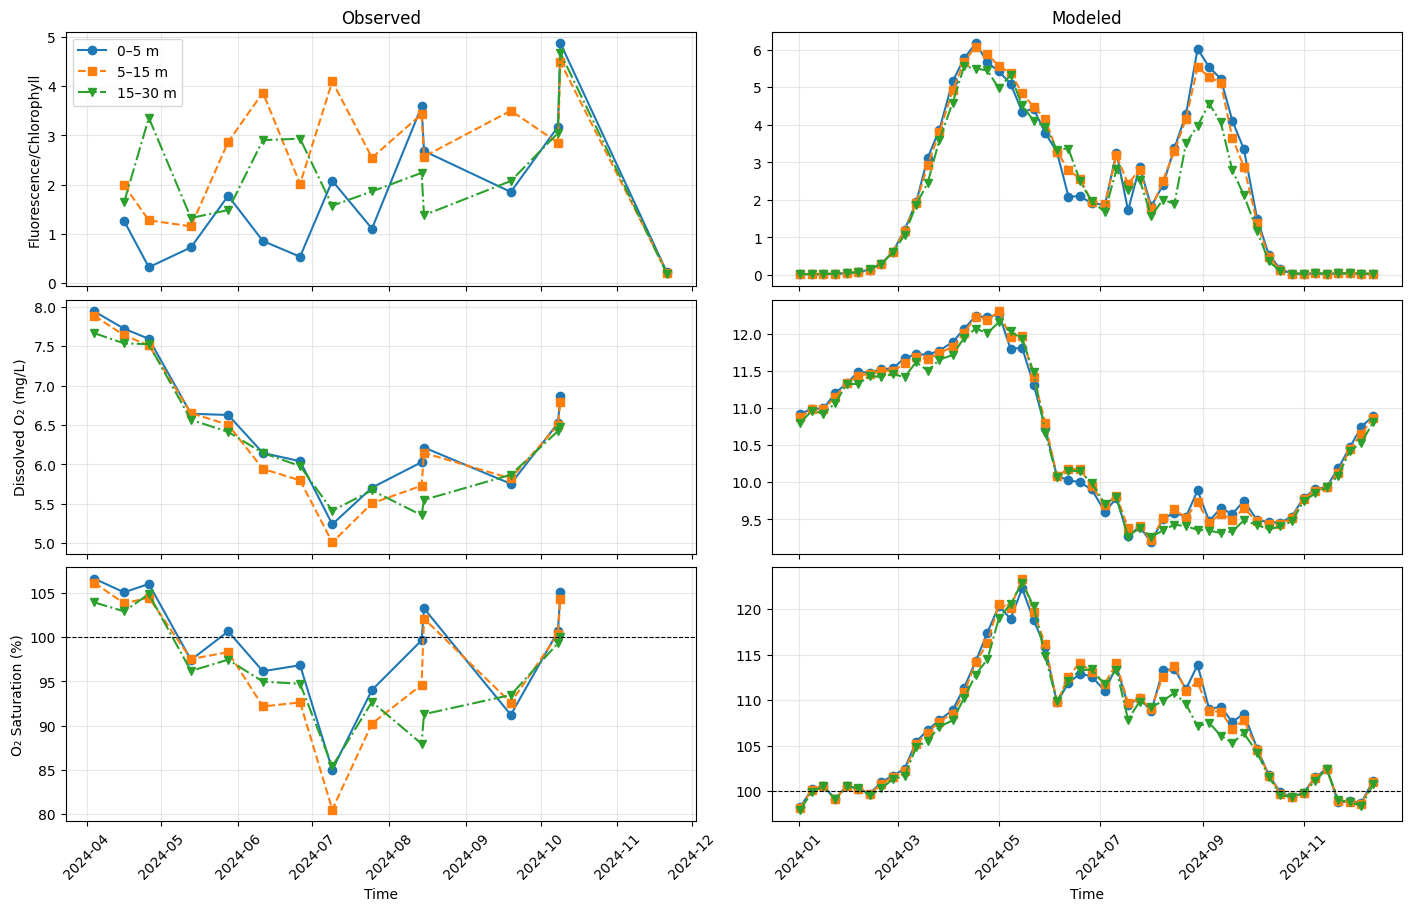

In [85]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(
    nrows=3, ncols=2, figsize=(14, 9), sharex="col", constrained_layout=True
)

depth_labels = ["0–5 m", "5–15 m", "15–30 m"]

# ==================================================
# Fluorescence
# ==================================================
# Observed (left)
axs[0, 0].plot(
    fl_0_5.time, fl_0_5, label=depth_labels[0], linestyle="-", marker="o"
)
axs[0, 0].plot(
    fl_5_15.time, fl_5_15, label=depth_labels[1], linestyle="--", marker="s"
)
axs[0, 0].plot(
    fl_15_30.time, fl_15_30, label=depth_labels[2], linestyle="-.", marker="v"
)
axs[0, 0].set_title("Observed")
axs[0, 0].set_ylabel("Fluorescence/Chlorophyll")
axs[0, 0].legend()
axs[0, 0].grid(alpha=0.3)

# Modeled (right)
axs[0, 1].plot(chl_0_5.time, chl_0_5, linestyle="-", marker="o")
axs[0, 1].plot(chl_5_15.time, chl_5_15, linestyle="--", marker="s")
axs[0, 1].plot(chl_15_30.time, chl_15_30, linestyle="-.", marker="v")
axs[0, 1].set_title("Modeled")
axs[0, 1].grid(alpha=0.3)

# ==================================================
# Oxygen
# ==================================================
# Observed
axs[1, 0].plot(o2_0_5_obs.time, o2_0_5_obs, linestyle="-", marker="o")
axs[1, 0].plot(o2_5_15_obs.time, o2_5_15_obs, linestyle="--", marker="s")
axs[1, 0].plot(o2_15_30_obs.time, o2_15_30_obs, linestyle="-.", marker="v")
axs[1, 0].set_ylabel("Dissolved O₂ (mg/L)")  # Added units here
axs[1, 0].grid(alpha=0.3)

# Modeled
axs[1, 1].plot(o2_0_5.time, o2_0_5 * 0.032, linestyle="-", marker="o")
axs[1, 1].plot(o2_5_15.time, o2_5_15 * 0.032, linestyle="--", marker="s")
axs[1, 1].plot(o2_15_30.time, o2_15_30 * 0.032, linestyle="-.", marker="v")
axs[1, 1].grid(alpha=0.3)

# ==================================================
# Oxygen saturation
# ==================================================
# Observed
axs[2, 0].plot(sat_0_5_obs.time, sat_0_5_obs, linestyle="-", marker="o")
axs[2, 0].plot(sat_5_15_obs.time, sat_5_15_obs, linestyle="--", marker="s")
axs[2, 0].plot(sat_15_30_obs.time, sat_15_30_obs, linestyle="-.", marker="v")
axs[2, 0].axhline(100, color="k", linestyle="--", linewidth=0.8)
axs[2, 0].set_ylabel("O₂ Saturation (%)")
axs[2, 0].set_xlabel("Time")
axs[2, 0].grid(alpha=0.3)

# Modeled
axs[2, 1].plot(sat_0_5.time, sat_0_5, linestyle="-", marker="o")
axs[2, 1].plot(sat_5_15.time, sat_5_15, linestyle="--", marker="s")
axs[2, 1].plot(sat_15_30.time, sat_15_30, linestyle="-.", marker="v")
axs[2, 1].axhline(100, color="k", linestyle="--", linewidth=0.8)
axs[2, 1].set_xlabel("Time")
axs[2, 1].grid(alpha=0.3)

for ax in axs.flat:
    ax.tick_params(axis="x", rotation=45)

plt.show()

In [86]:
import gsw
import numpy as np

# -----------------------------
# Time window
# -----------------------------
obs_sel = obs.sel(time=slice(months_string_begin, months_string_end))

# -----------------------------
# APPLY QC MASK (CRITICAL STEP)
# -----------------------------
qc_mask = (
    (obs_sel["Oxygen_CTD_flag"] == 2) &
    (obs_sel["TEMP_flag"] == 2)
)
qc_mask1 = (
    (obs_sel["Fluor_CTD_flag"] == 2)
)

# Apply mask to relevant variables
obs_qc = obs_sel.copy()

obs_qc["Oxygen_CTD"]     = obs_sel["Oxygen_CTD"].where(qc_mask)
obs_qc["Temperature_CTD"] = obs_sel["Temperature_CTD"].where(qc_mask)
obs_qc["Fluor_CTD"] = obs_sel["Fluor_CTD"].where(qc_mask1)

# Optional but recommended: also mask salinity consistently
if "Salinity_CTD_flag" in obs_sel:
    sal_mask = obs_sel["Salinity_CTD_flag"] == 2
    obs_qc["Salinity_CTD"] = obs_sel["Salinity_CTD"].where(qc_mask & sal_mask)
else:
    obs_qc["Salinity_CTD"] = obs_sel["Salinity_CTD"].where(qc_mask)

# -----------------------------
# Average across stations
# -----------------------------
obs_mean = obs_qc.sel(HV=[1,3,5,7,9,10,12]).mean(dim="HV", skipna=True)


# -----------------------------
# UNIT CONVERSION (to mL/L)
# -----------------------------
ML_PER_UMOLKG = 1 / 44.66


# -----------------------------
# Prepare variables
# -----------------------------
SP = obs_mean["Salinity_CTD"]
t  = obs_mean["Temperature_CTD"]


# -----------------------------
# Oxygen saturation (µmol/kg)
# -----------------------------
o2_sat = xr.apply_ufunc(
    gsw.O2sol_SP_pt,
    SP,
    t
)

obs_mean["O2_sat"] = 100.0 * obs_mean['Oxygen_CTD'] / (o2_sat*ML_PER_UMOLKG)

# -----------------------------
# Depth-averaging function
# -----------------------------
def depth_avg_timeseries(ds, var, zmin, zmax):
    return ds[var].sel(depth=slice(zmin, zmax)).mean(dim="depth", skipna=True)

# -----------------------------
# Fluorescence (unchanged)
# -----------------------------
fl_0_5   = depth_avg_timeseries((obs_mean), "Fluor_CTD", 0, 5)
fl_5_15  = depth_avg_timeseries((obs_mean), "Fluor_CTD", 5, 15)
fl_15_30 = depth_avg_timeseries((obs_mean), "Fluor_CTD", 15, 30)

# -----------------------------
# Observed oxygen (QC-filtered)
# -----------------------------
o2_0_5_obs   = depth_avg_timeseries(obs_mean, "Oxygen_CTD", 0, 5)
o2_5_15_obs  = depth_avg_timeseries(obs_mean, "Oxygen_CTD", 5, 15)
o2_15_30_obs = depth_avg_timeseries(obs_mean, "Oxygen_CTD", 15, 30)

# -----------------------------
# Oxygen saturation
# -----------------------------
sat_0_5_obs   = depth_avg_timeseries(obs_mean, "O2_sat", 0, 5)
sat_5_15_obs  = depth_avg_timeseries(obs_mean, "O2_sat", 5, 15)
sat_15_30_obs = depth_avg_timeseries(obs_mean, "O2_sat", 15, 30)

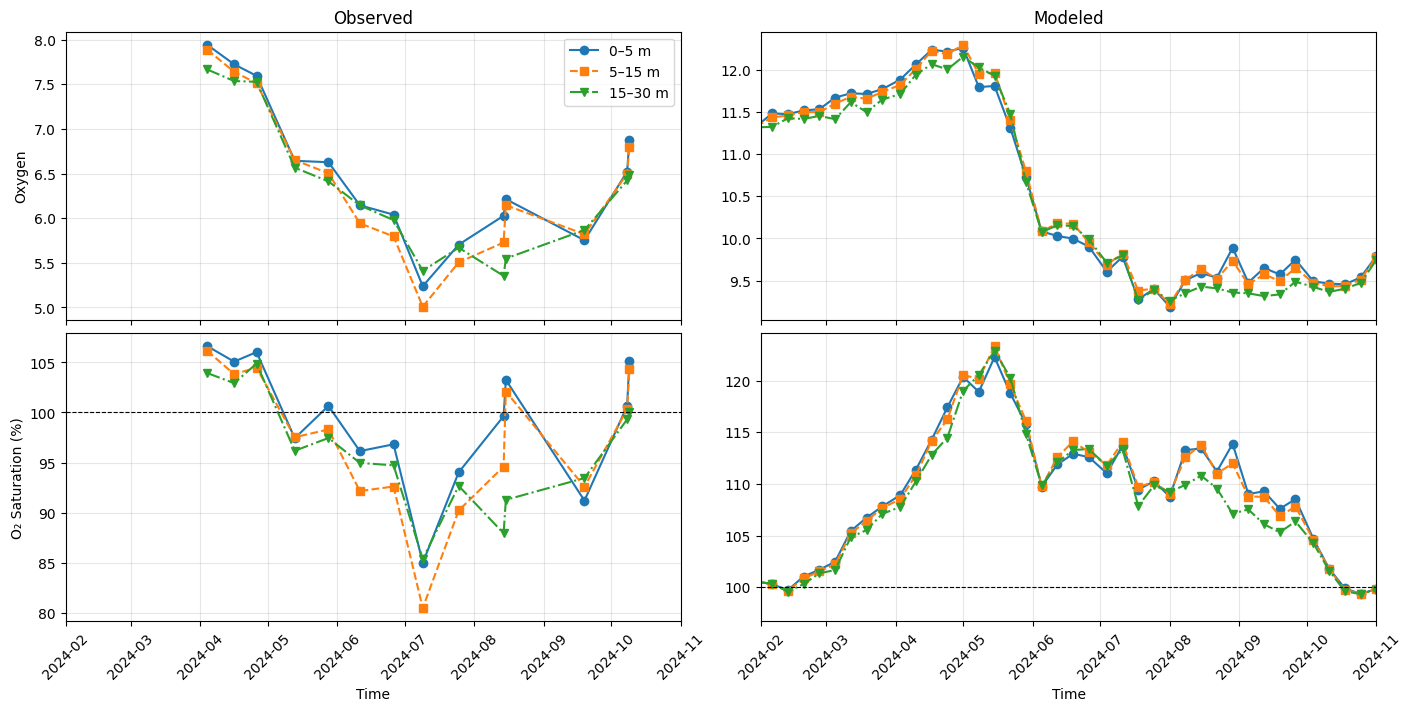

In [87]:
fig, axs = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(14, 7),
    sharex="col",
    constrained_layout=True
)

depth_labels = ["0–5 m", "5–15 m", "15–30 m"]

# ==================================================
# Oxygen
# ==================================================
# Observed (left)
axs[0, 0].plot(o2_0_5_obs.time, o2_0_5_obs, linestyle='-', marker='o', label=depth_labels[0])
axs[0, 0].plot(o2_5_15_obs.time, o2_5_15_obs, linestyle='--', marker='s', label=depth_labels[1])
axs[0, 0].plot(o2_15_30_obs.time, o2_15_30_obs, linestyle='-.', marker='v', label=depth_labels[2])
axs[0, 0].set_title("Observed")
axs[0, 0].set_ylabel("Oxygen")
axs[0, 0].legend()
axs[0, 0].grid(alpha=0.3)

# Modeled (right)
axs[0, 1].plot(o2_0_5.time, o2_0_5 * 0.032, linestyle='-', marker='o')
axs[0, 1].plot(o2_5_15.time, o2_5_15 * 0.032, linestyle='--', marker='s')
axs[0, 1].plot(o2_15_30.time, o2_15_30 * 0.032, linestyle='-.', marker='v')
axs[0, 1].set_title("Modeled")
axs[0, 1].grid(alpha=0.3)

# ==================================================
# Oxygen saturation
# ==================================================
# Observed
axs[1, 0].plot(sat_0_5_obs.time, sat_0_5_obs, linestyle='-', marker='o')
axs[1, 0].plot(sat_5_15_obs.time, sat_5_15_obs, linestyle='--', marker='s')
axs[1, 0].plot(sat_15_30_obs.time, sat_15_30_obs, linestyle='-.', marker='v')
axs[1, 0].axhline(100, color="k", linestyle="--", linewidth=0.8)
axs[1, 0].set_ylabel("O₂ Saturation (%)")
axs[1, 0].set_xlabel("Time")
axs[1, 0].grid(alpha=0.3)

# Modeled
axs[1, 1].plot(sat_0_5.time, sat_0_5, linestyle='-', marker='o')
axs[1, 1].plot(sat_5_15.time, sat_5_15, linestyle='--', marker='s')
axs[1, 1].plot(sat_15_30.time, sat_15_30, linestyle='-.', marker='v')
axs[1, 1].axhline(100, color="k", linestyle="--", linewidth=0.8)
axs[1, 1].set_xlabel("Time")
axs[1, 1].grid(alpha=0.3)

for ax in axs.flat:
    ax.tick_params(axis="x", rotation=45)

import pandas as pd

t_start = pd.Timestamp("2024-02-01")
t_end   = pd.Timestamp("2024-11-01")

for ax in axs.flat:
    ax.set_xlim(t_start, t_end)

plt.show()

## Oxygen Hovmöller diagrams

Depth–time oxygen sections for stations 1, 5 and 10 from the QC-filtered observations and from the model (converted from mmol m⁻³ to mL L⁻¹), on a common colour scale over the observation period.

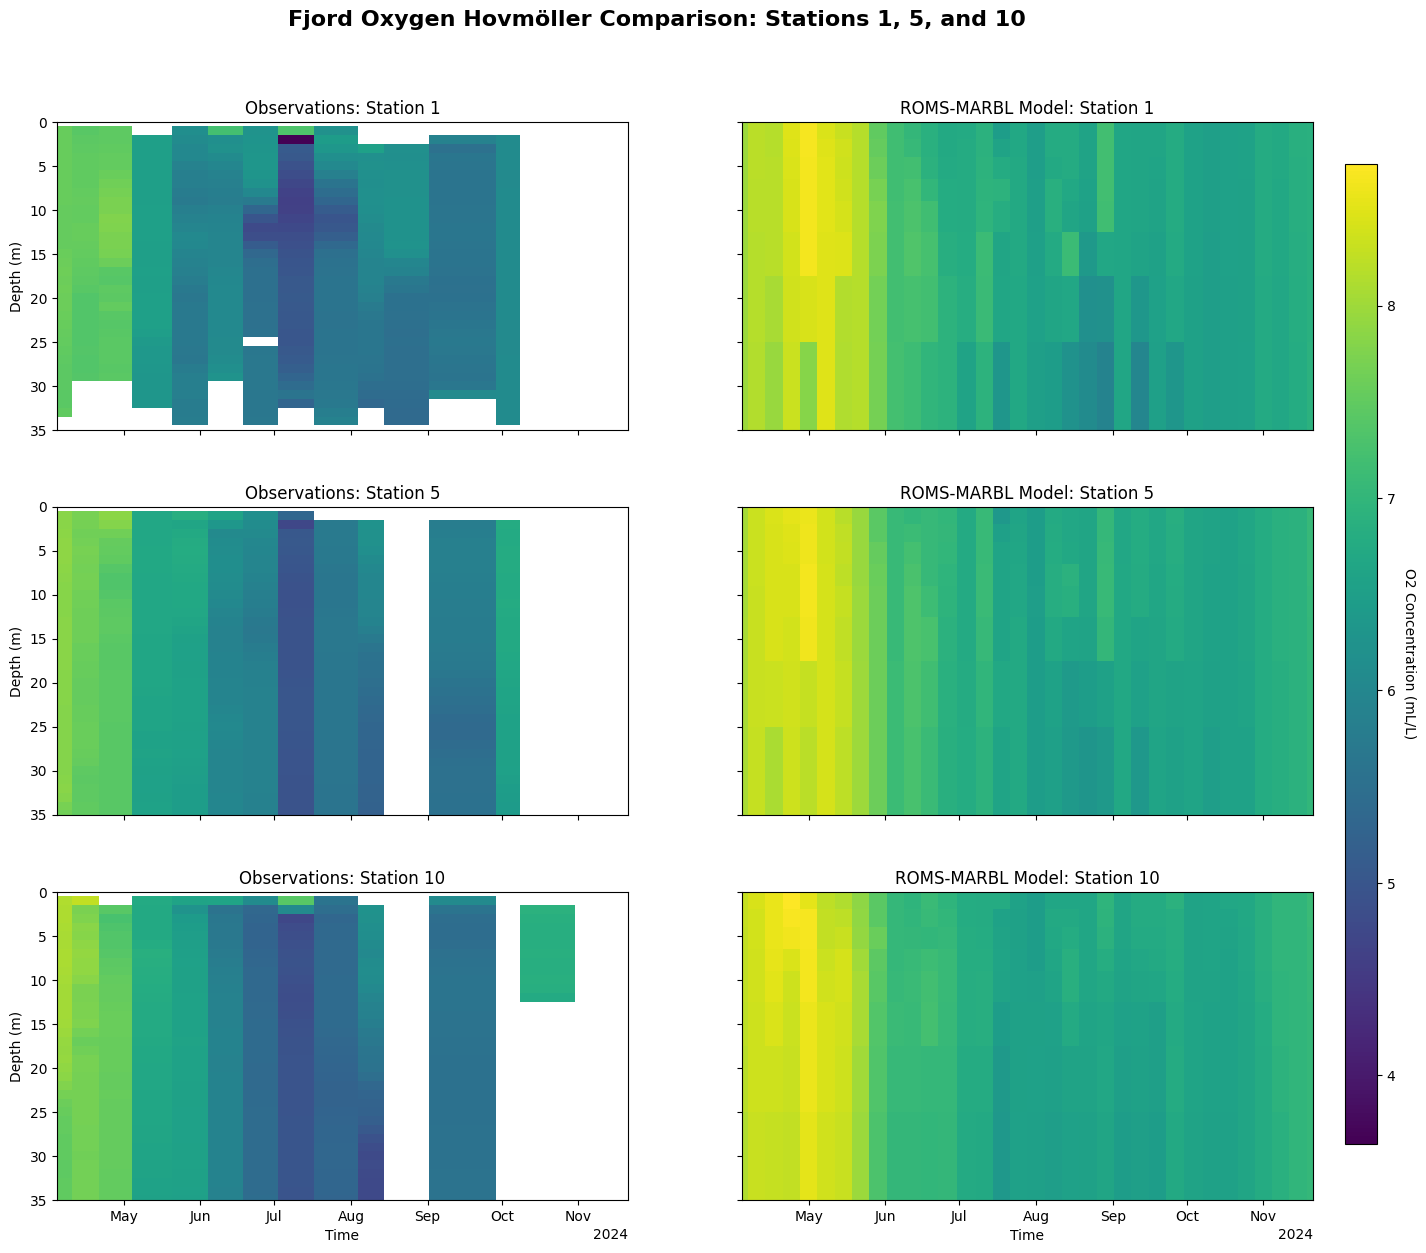

In [88]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

# --- Target stations map ---
# Format: (Station ID/HV index, index in the model 'locations' list)
target_stations = [
    {"id": 1, "model_idx": 0},
    {"id": 5, "model_idx": 2},  
    {"id": 10, "model_idx": 5}, 
]

MMOL_M3_TO_ML_L = 22.393 / 1000.0

# ----------------------------------------------------------------
# 1. PRE-PROCESS DATA FOR THE CHOSEN STATIONS
# ----------------------------------------------------------------
obs_sel = obs.sel(time=slice(months_string_begin, months_string_end))
qc_mask = (obs_sel["Oxygen_CTD_flag"] == 2) & (obs_sel["TEMP_flag"] == 2)
obs_qc = obs_sel.copy()
obs_qc["Oxygen_CTD"] = obs_sel["Oxygen_CTD"].where(qc_mask)

obs_dict = {}
model_dict = {}
all_min, all_max = [], []

for stat in target_stations:
    st_id = stat["id"]
    m_idx = stat["model_idx"]
    
    # Process Observations
    obs_stat = obs_qc.sel(HV=st_id)
    obs_hov = obs_stat["Oxygen_CTD"].transpose("depth", "time")
    obs_dict[st_id] = obs_hov
    
    # Process Model
    lat_st, lon_st = locations[m_idx]
    model_stat = O2.sel(lat=lat_st, lon=lon_st, method="nearest")
    model_hov = (model_stat * MMOL_M3_TO_ML_L).transpose("depth", "time")
    model_dict[st_id] = model_hov
    
    all_min.extend([float(obs_hov.min(skipna=True)), float(model_hov.min(skipna=True))])
    all_max.extend([float(obs_hov.max(skipna=True)), float(model_hov.max(skipna=True))])

vmin = min(all_min)
vmax = max(all_max)

# ----------------------------------------------------------------
# 2. EXTRACT TIME BOUNDS FROM OBSERVATIONS
# ----------------------------------------------------------------
# Get the global min and max time bounds from the observations to lock the axes
t_start = obs_qc["time"].min().values
t_end = obs_qc["time"].max().values


# ----------------------------------------------------------------
# 3. MULTI-PANEL PLOTTING (Grid: 3 Rows x 2 Columns)
# ----------------------------------------------------------------
fig, axes = plt.subplots(3, 2, figsize=(16, 14), sharex=True, sharey=True)

for idx, stat in enumerate(target_stations):
    st_id = stat["id"]
    
    # Row idx, Column 0: Observations
    im_obs = obs_dict[st_id].plot(
        ax=axes[idx, 0],
        x="time",
        y="depth",
        yincrease=False,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False
    )
    axes[idx, 0].set_title(f"Observations: Station {st_id}")
    axes[idx, 0].set_ylabel("Depth (m)")
    axes[idx, 0].set_xlabel("")
    
    # Explicitly set X limits to cover full observation timeline
    axes[idx, 0].set_xlim(t_start, t_end)
    
    # Row idx, Column 1: Model
    im_model = model_dict[st_id].plot(
        ax=axes[idx, 1],
        x="time",
        y="depth",
        yincrease=False,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False
    )
    axes[idx, 1].set_title(f"ROMS-MARBL Model: Station {st_id}")
    axes[idx, 1].set_ylabel("") 
    axes[idx, 1].set_xlabel("")
    
    # Force the model axis to match the observation time extension
    axes[idx, 1].set_xlim(t_start, t_end)

# Restore X-axis labels to the bottom-most row only
axes[2, 0].set_xlabel("Time")
axes[2, 1].set_xlabel("Time")

# Add a single master colorbar on the right side
cbar_ax = fig.add_axes([0.93, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im_model, cax=cbar_ax)
cbar.set_label("O2 Concentration (mL/L)", rotation=270, labelpad=15)

plt.suptitle(
    "Fjord Oxygen Hovmöller Comparison: Stations 1, 5, and 10",
    fontsize=16,
    weight="bold",
    y=0.96,
)

plt.subplots_adjust(right=0.91, hspace=0.25) 
plt.show()